# 6 · Value iteration against policy iteration

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shimmeringvoid/MDP_Experiments/blob/main/notebooks/06_value_vs_policy_iteration.ipynb)

The report compared its two planners on both MDPs and came away with three observations and a
guess:

1. policy iteration always needs far fewer iterations than value iteration;
2. on the grid world it is nevertheless *slower*, while on the elevator it is *faster*;
3. value iteration's iteration count on random grid worlds is erratic;

> "Perhaps MDPs with a large number of actions are better suited to policy-iteration, while
> value-iteration does better for MDPs with fewer numbers of actions."

Notebooks 2 and 4 reproduced the observations. This one explains them. The guess turns out to be
right, and can be sharpened into a rule of thumb. The erratic counts turn out to measure something
quite specific about a world, and it is not its size.

In [ ]:
# Only needed on Google Colab, which opens this notebook without the rest of the repository:
# fetch the repository and put its library on the path.  Anywhere else this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    if not os.path.isdir("MDP_Experiments"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/shimmeringvoid/MDP_Experiments"], check=True)
    sys.path.insert(0, os.path.abspath("MDP_Experiments/src"))

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from IPython.display import Markdown, display

import mdplab as ml
from mdplab import plotting as mp

mp.use_style()
pd.options.display.float_format = "{:,.2f}".format

world = ml.GridWorld.report_figure1()
grid = world.mdp
elevator = ml.crazy_elevator(50)

## Counting work instead of seconds

Seconds depend on how the code is written (notebook 2 saw the grid-world ranking flip between
loop code and matrix code). A fairer unit is the **backup**: one evaluation of

$$r(s,a) + \gamma \sum_{s'} p(s' \mid s,a)\,V(s')$$

for a single state and action. Every algorithm here is built from backups, and in loop-style code
running time is proportional to their number.

* A sweep of **value iteration** backs up every action in every state: $S \times A$ backups.
* **Policy iteration** alternates two steps. *Evaluating* the current policy by sweeping costs only
  $S$ backups per sweep, since each state has one action to follow, but takes many sweeps.
  *Improving* it costs $S \times A$, once per round.

The textbook version of policy iteration, and by every indication the 2014 one, evaluates each
policy by sweeping until the values stop moving, starting again from zero in every round.

In [2]:
def work(mdp, policy0=None):
    vi = ml.value_iteration(mdp, tol=1e-6)
    pi = ml.policy_iteration(mdp, evaluation="iterative", eval_tol=1e-6, warm_start=False, policy0=policy0)
    return vi, pi


rows_out, detail = [], {}
for name, mdp, policy0, ratio_2014 in (
    ("grid world 7 × 8", grid, np.full(grid.n_states, 3), 11.42 / 1.78),
    ("crazy elevator, 50 floors", elevator, None, None),
):
    vi, pi = work(mdp, policy0)
    detail[name] = (vi, pi)
    rows_out.append({
        "MDP": name,
        "states × actions": f"{mdp.n_active} × {mdp.n_actions}",
        "VI sweeps": vi.iterations,
        "VI backups": vi.backups,
        "PI rounds": pi.iterations,
        "PI evaluation sweeps": int(pi.history["eval_sweeps"].sum()),
        "PI backups": pi.backups,
        "PI backups / VI backups": pi.backups / vi.backups,
    })
pd.DataFrame(rows_out).set_index("MDP")

,states × actions,VI sweeps,VI backups,PI rounds,PI evaluation sweeps,PI backups,PI backups / VI backups
MDP,,,,,,,
grid world 7 × 8,42 × 4,159,26712,6,4560,192528,7.21
"crazy elevator, 50 floors",49 × 50,350,857500,3,1198,66052,0.08


Counted in backups, policy iteration does about seven times the work of value iteration on the
grid world and about a thirteenth of it on the elevator. The report's timings for the grid world
of Figure 1 were 11.42 s against 1.78 s, a factor of 6.4. So the backup count reproduces the 2014
result without a stopwatch, which also means the result was never about the machine or the
language: in 2014, as now, policy iteration with swept evaluation simply did more arithmetic on
the grid world and less on the elevator.

## Where policy iteration's sweeps go

Why is the balance so different? The number of rounds is small in both cases. The difference is
in what each round costs.

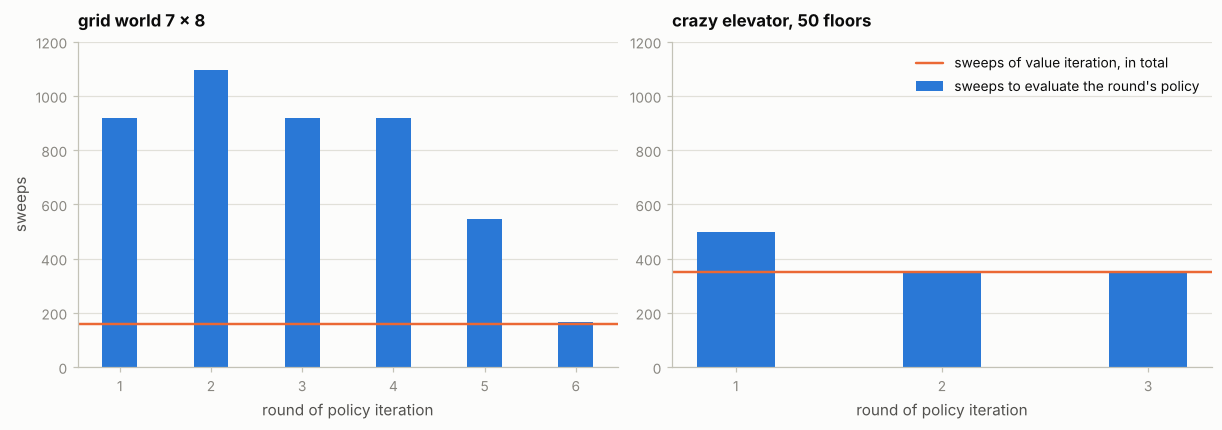

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (name, (vi, pi)) in zip(axes, detail.items()):
    sweeps = pi.history["eval_sweeps"]
    ax.bar(np.arange(1, len(sweeps) + 1), sweeps, width=0.38, color=mp.SERIES[0], label="sweeps to evaluate the round's policy")
    ax.axhline(vi.iterations, color=mp.SERIES[1], linewidth=1.6, label="sweeps of value iteration, in total")
    ax.set_xticks(np.arange(1, len(sweeps) + 1))
    ax.set(xlabel="round of policy iteration", title=name, ylim=(0, 1200))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("sweeps")
axes[1].legend(loc="upper right")
mp.savefig(fig, "06_sweeps_per_round");

On the elevator each evaluation takes about as many sweeps as the whole of value iteration, and
there are three of them. But an evaluation sweep costs one backup per floor where a value-iteration
sweep costs fifty, so policy iteration comes out far ahead.

On the grid world an evaluation sweep is only four times cheaper, there are six rounds, and, the
decisive part, most evaluations take **918 sweeps or more**, six times as many as value iteration
needs in total. That number has appeared before (notebook 2), and here is where it comes from.

The early policies of policy iteration are poor. Under "always go left" the agent walks left until
something stops it, and wherever that is the edge of the grid it stays there for good. For such a
cell the evaluation computes the value of an endless stream of 0.01 costs, $-0.01\,(1 + \gamma + \gamma^2 + \dots)$, one term per sweep. The
increments shrink by exactly $\gamma = 0.99$ per sweep, the slowest rate a discounted problem
allows, and fall below the tolerance of $10^{-6}$ only when

$$0.01 \times 0.99^{\,k-1} < 10^{-6} \quad\Longleftrightarrow\quad k \ge 918 .$$

Any policy that leaves some cell bumping into a wall for ever costs 918 sweeps to evaluate. On the
elevator this cannot happen: every button has some chance of reaching the ground floor from every
floor, so every policy, however bad, ends its rides.

## Testing the conjecture

The grid world has few actions *and* bad intermediate policies; the elevator has many actions and
none. To separate the two effects, the number of actions has to be varied on its own. Two
controlled families do that:

* the **50-floor elevator with a smaller button panel**: only buttons 0 to $A-1$ work, for
  $A$ from 2 to 50. The states stay the same;
* **random MDPs** ("Garnets") with 200 states, 5 possible outcomes per action and $A$ actions from
  2 to 64, five instances of each.

If the report's guess is right, the ratio of value iteration's work to policy iteration's should
rise with $A$ in both.

In both families the advantage of policy iteration grows in proportion to the number of actions. Break-even is at about 3 buttons on the elevator and between 4 and 8 actions for the random MDPs.

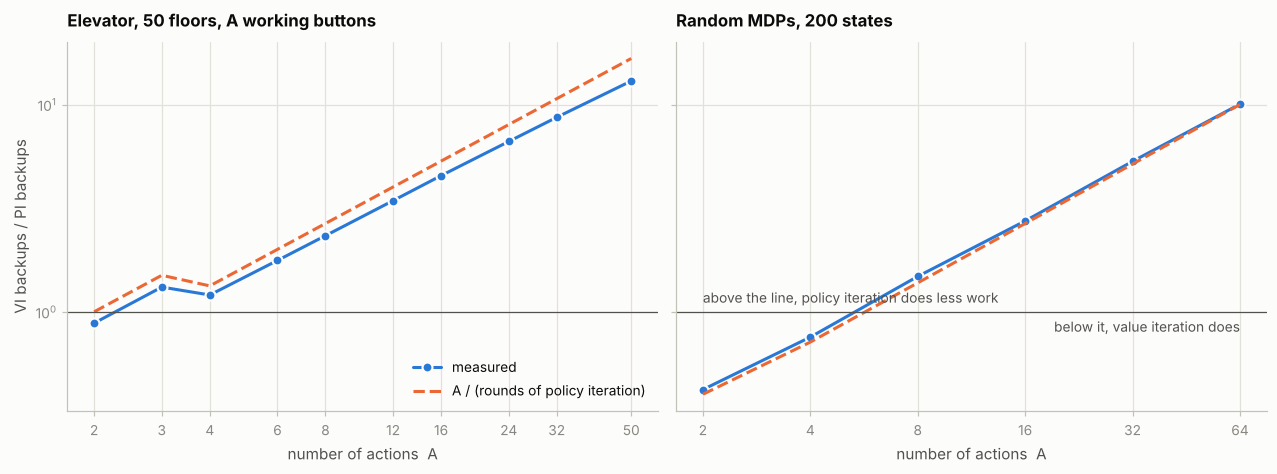

In [4]:
panel_sizes = [2, 3, 4, 6, 8, 12, 16, 24, 32, 50]
panel = []
for A in panel_sizes:
    vi, pi = work(ml.crazy_elevator(50, buttons=A))
    panel.append((A, vi.backups / pi.backups, pi.iterations))
panel = pd.DataFrame(panel, columns=["A", "ratio", "rounds"]).set_index("A")

garnet_sizes = [2, 4, 8, 16, 32, 64]
garnet = []
for A in garnet_sizes:
    runs = [work(ml.garnet(200, A, 5, gamma=0.99, seed=seed)) for seed in range(5)]
    garnet.append((A, np.mean([vi.backups / pi.backups for vi, pi in runs]), np.mean([pi.iterations for _, pi in runs])))
garnet = pd.DataFrame(garnet, columns=["A", "ratio", "rounds"]).set_index("A")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for ax, data, title in ((axes[0], panel, "Elevator, 50 floors, A working buttons"), (axes[1], garnet, "Random MDPs, 200 states")):
    ax.plot(data.index, data.ratio, "o-", color=mp.SERIES[0], label="measured")
    ax.plot(data.index, data.index / data.rounds, color=mp.SERIES[1], linestyle="--", label="A / (rounds of policy iteration)")
    ax.axhline(1, color=mp.INK_SECONDARY, linewidth=0.8)
    ax.set(xscale="log", yscale="log", xlabel="number of actions  A", title=title)
    ax.set_xticks(data.index, [str(a) for a in data.index])
    ax.minorticks_off()
axes[0].set_ylabel("VI backups / PI backups")
axes[1].annotate("above the line, policy iteration does less work", (2, 1), xytext=(0, 6), textcoords="offset points", fontsize=9, color=mp.INK_SECONDARY)
axes[1].annotate("below it, value iteration does", (64, 1), xytext=(0, -13), textcoords="offset points", ha="right", fontsize=9, color=mp.INK_SECONDARY)
axes[0].legend(loc="lower right")
mp.savefig(fig, "06_action_count")

display(Markdown(
    f"In both families the advantage of policy iteration grows in proportion to the number of actions. "
    f"Break-even is at about {panel.index[(panel.ratio > 1).values.argmax()]} buttons on the elevator and between "
    f"{garnet.index[(garnet.ratio > 1).values.argmax() - 1]} and {garnet.index[(garnet.ratio > 1).values.argmax()]} actions for the random MDPs."
))

The report's guess holds, and the dashed line makes it quantitative:

$$\frac{\text{work of value iteration}}{\text{work of policy iteration}} \;\approx\; \frac{A}{K},$$

where $K$ is the number of rounds policy iteration needs. The reasoning takes two lines. Value
iteration needs some number $I$ of sweeps at $S \times A$ backups each. Policy iteration needs $K$
evaluations; each takes about $I$ sweeps as well, because evaluating a policy and running value
iteration converge at similar rates, but at only $S$ backups per sweep. The ratio is
$I S A / (K I S) = A/K$.

Since $K$ is small and barely grows (3 on the elevator, 5 to 6 for the random MDPs), **policy
iteration wins once there are more actions than rounds.** With four actions and six to nine rounds
the grid world is on the wrong side of that line by itself, before its 918-sweep evaluations
make matters worse.

## Getting the best of both

The two algorithms are the ends of a dial. *Modified policy iteration* improves the policy, then
runs a fixed number $m$ of evaluation sweeps, then improves again. With $m = 0$ it is value
iteration; as $m$ grows it becomes policy iteration. Neither end is the best setting.

The best setting needs **2.8 times fewer** backups than value iteration on the grid world (at m = 10) and **27 times fewer** on the elevator (at m = 100). Against textbook policy iteration the saving on the grid world is a factor of 20.

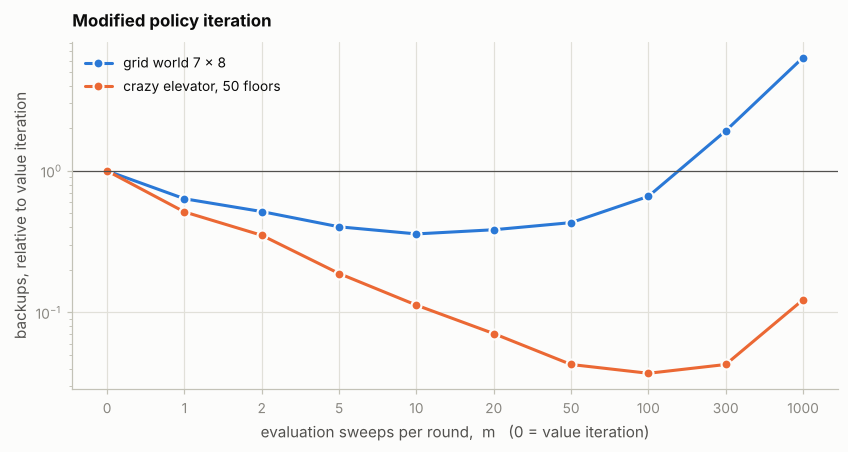

In [5]:
ms = [0, 1, 2, 5, 10, 20, 50, 100, 300, 1000]
dial = pd.DataFrame(
    {name: [ml.modified_policy_iteration(mdp, m=m, tol=1e-6).backups for m in ms] for name, mdp in (("grid world 7 × 8", grid), ("crazy elevator, 50 floors", elevator))},
    index=pd.Index(ms, name="m"),
)
relative = dial / dial.loc[0]

fig, ax = plt.subplots(figsize=(7.6, 4))
positions = np.arange(len(ms))
for (name, column), colour in zip(relative.items(), mp.SERIES):
    ax.plot(positions, column, "o-", color=colour, label=name)
ax.axhline(1, color=mp.INK_SECONDARY, linewidth=0.8)
ax.set_xticks(positions, [str(m) for m in ms])
ax.set(yscale="log", xlabel="evaluation sweeps per round,  m   (0 = value iteration)", ylabel="backups, relative to value iteration", title="Modified policy iteration")
ax.legend()
mp.savefig(fig, "06_modified_policy_iteration")

best = relative.idxmin()
display(Markdown(
    f"The best setting needs **{1 / relative.min().iloc[0]:.1f} times fewer** backups than value iteration on the grid world "
    f"(at m = {best.iloc[0]}) and **{1 / relative.min().iloc[1]:.0f} times fewer** on the elevator (at m = {best.iloc[1]}). "
    f"Against textbook policy iteration the saving on the grid world is a factor of "
    f"{detail['grid world 7 × 8'][1].backups / dial['grid world 7 × 8'].min():.0f}."
))

Somewhere between ten and a hundred evaluation sweeps per round collects policy iteration's
benefit without its cost, because there is no point in evaluating a bad policy to six decimal
places before replacing it. (Evaluating exactly, by solving the linear system, is the other way out, and
is what `mdplab.policy_iteration` does by default. It moves the cost out of backups and into
linear algebra, which is cheap at these sizes.)

## Why value iteration's count is erratic

Notebook 2 showed the pattern in the report's Figure 2: for random worlds of one size, the number
of sweeps is either 918 or scattered far below. The 918 has just been explained for policies; the
same mechanism applies to the optimal policy itself.

Once value iteration's greedy policy has settled on the optimal one, each sweep shrinks the
remaining error by the factor $\gamma\rho$, where $\rho$ is the largest eigenvalue of the optimal
policy's transition matrix among the non-terminal cells. $\rho$ measures how *sticky* the world is
under its best policy: the chance, in the stickiest place, that the agent is still wandering
after one more move. If a pit or the goal is reached quickly from everywhere, $\rho$ is small. If
somewhere the best move is to wait at a wall for a one-in-ten slip, $\rho = 0.9$. If somewhere the
best the agent can do is to wait for ever, $\rho = 1$.

In [6]:
def stickiness(mdp, policy):
    """Largest eigenvalue of the policy's transition matrix restricted to non-terminal states."""
    P_pi, _ = mdp.policy_model(policy)
    idx = np.flatnonzero(mdp.active)
    block = sp.csr_matrix(P_pi)[idx][:, idx]
    if idx.size <= 500:
        return float(np.abs(np.linalg.eigvals(block.toarray())).max())
    return float(np.abs(spla.eigs(block.astype(float), k=1, which="LM", return_eigenvectors=False)[0]))


rng = np.random.default_rng(6)
records = []
for rows, cols in [(5, 5), (7, 8), (10, 10), (15, 15), (20, 20)]:
    for _ in range(40):
        w = ml.GridWorld.random(rows, cols, seed=rng)
        plan = ml.policy_iteration(w.mdp)
        records.append({
            "states": rows * cols,
            "sweeps": ml.value_iteration(w.mdp, tol=1e-6).iterations,
            "rho": stickiness(w.mdp, plan.policy),
            "waits for ever": bool((~ml.absorption(w.mdp, plan.policy).proper & w.free).any()),
        })
worlds = pd.DataFrame(records)
rho_fig1 = stickiness(grid, ml.policy_iteration(grid).policy)

* For the 144 worlds whose optimal policy always finishes, the formula on the curve predicts the sweep count with a correlation of **0.990**. The size of the world plays no part in it.
* Of the 56 worlds with a cell that waits for ever, **56** take exactly 918 sweeps.
* The world of Figure 1 has ρ = 0.90: its two wait-at-the-wall cells. That is why it needs 159 sweeps although a path from any cell to the goal is at most a dozen moves long.

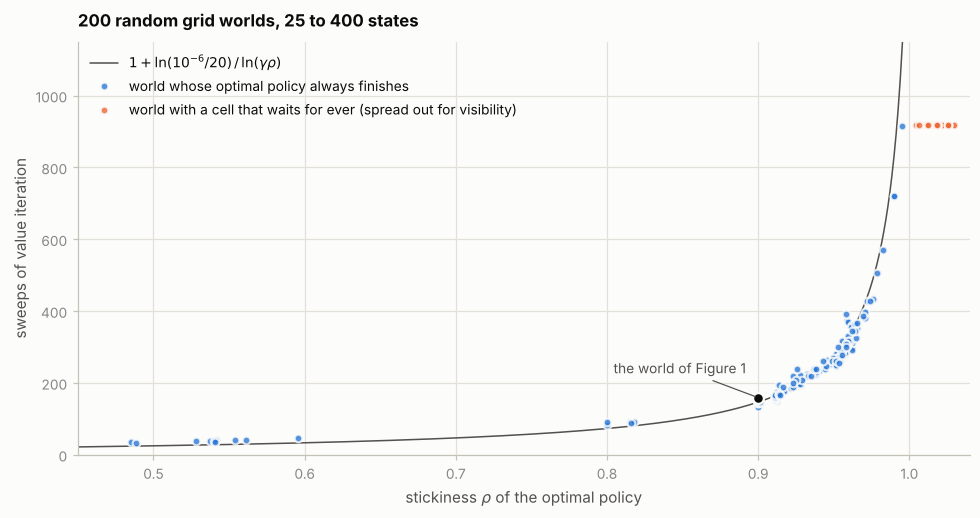

In [7]:
ends = worlds[~worlds["waits for ever"]]
never = worlds[worlds["waits for ever"]]
rho_line = np.linspace(0.45, 0.9995, 400)
predicted = lambda rho, scale=20.0: 1 + np.log(1e-6 / scale) / np.log(0.99 * rho)

fig, ax = plt.subplots(figsize=(8.8, 4.6))
ax.plot(rho_line, predicted(rho_line), color=mp.INK_SECONDARY, linewidth=1, label=r"$1 + \ln(10^{-6}/20)\,/\,\ln(\gamma\rho)$")
ax.plot(ends.rho, ends.sweeps, "o", color=mp.SERIES[0], markersize=5, alpha=0.8, label="world whose optimal policy always finishes")
ax.plot(never.rho + rng.uniform(0.004, 0.03, len(never)), never.sweeps, "o", color=mp.SERIES[1], markersize=5, alpha=0.8, label="world with a cell that waits for ever (spread out for visibility)")
ax.plot(rho_fig1, detail["grid world 7 × 8"][0].iterations, "o", color=mp.INK, markersize=7)
ax.annotate("the world of Figure 1", (rho_fig1, 159), xytext=(-8, 16), textcoords="offset points", ha="right", fontsize=9, color=mp.INK_SECONDARY,
            arrowprops=dict(arrowstyle="-", color=mp.INK_SECONDARY, linewidth=0.8))
ax.set(xlabel=r"stickiness $\rho$ of the optimal policy", ylabel="sweeps of value iteration", title="200 random grid worlds, 25 to 400 states", ylim=(0, 1150), xlim=(0.45, 1.04))
ax.legend(loc="upper left")
mp.savefig(fig, "06_stickiness")

corr = np.corrcoef(predicted(ends.rho), ends.sweeps)[0, 1]
display(Markdown(
    f"* For the {len(ends)} worlds whose optimal policy always finishes, the formula on the curve predicts the sweep count with a "
    f"correlation of **{corr:.3f}**. The size of the world plays no part in it.\n"
    f"* Of the {len(never)} worlds with a cell that waits for ever, **{int((never.sweeps == 918).sum())}** take exactly 918 sweeps"
    + (".\n" if (never.sweeps == 918).all() else f" and the other {int((never.sweeps != 918).sum())} take more.\n") +
    f"* The world of Figure 1 has ρ = {rho_fig1:.2f}: its two wait-at-the-wall cells. That is why it needs 159 sweeps "
    f"although a path from any cell to the goal is at most a dozen moves long."
))

So the erratic curve of Figure 2 is not noise. Value iteration's sweep count is a measurement of
the stickiest spot in the world. Random worlds of the same size differ wildly in that, depending
on whether the dice happened to produce a cell squeezed between a pit and a wall, or a pocket with
no exit. Larger worlds have more chances to contain a pocket, which is why the average drifts up
towards 918 with size; and an average over 20 worlds jumps about because it is mostly counting how
many of the 20 have one.

### Most of those sweeps do not change the policy

A last observation, which the report had no way to make because its code only looked at the final
policy. The stopping rule waits for the *values* to settle to six decimal places. The *policy*
settles much earlier.

In [8]:
def first_optimal_sweep(mdp, V_star, tol=1e-6):
    """Sweep after which value iteration's greedy policy is optimal, and total sweeps to converge."""
    Q_star = mdp.q_values(V_star)
    states = np.arange(mdp.n_states)
    scale = max(1.0, np.abs(V_star).max())
    V, last_bad, k = np.zeros(mdp.n_states), 0, 0
    while True:
        k += 1
        Q = mdp.q_values(V)
        if (V_star - Q_star[states, Q.argmax(axis=1)])[mdp.active].max() > 1e-7 * scale:
            last_bad = k
        V_new = Q.max(axis=1)
        delta = np.abs(V_new - V).max()
        V = V_new
        if delta < tol:
            return last_bad + 1, k


rng = np.random.default_rng(7)
early = []
for rows, cols in [(5, 5), (7, 8), (10, 10), (15, 15), (20, 20), (30, 30)]:
    for _ in range(30):
        w = ml.GridWorld.random(rows, cols, seed=rng)
        a, b = first_optimal_sweep(w.mdp, ml.policy_iteration(w.mdp).V)
        early.append((rows * cols, a, b))
early = pd.DataFrame(early, columns=["states", "policy optimal after", "values converged after"])
early["share"] = early["policy optimal after"] / early["values converged after"]
table = early.groupby("states").median()
for name, mdp in (("Figure 1 world", grid), ("elevator, 50 floors", elevator)):
    a, b = first_optimal_sweep(mdp, ml.policy_iteration(mdp).V)
    table.loc[name] = (a, b, a / b)
table.rename(columns={"policy optimal after": "policy optimal after (sweeps)", "values converged after": "values converged after (sweeps)", "share": "share of the sweeps that mattered"})

,policy optimal after (sweeps),values converged after (sweeps),share of the sweeps that mattered
states,,,
25,14.00,226.00,0.07
56,30.00,271.50,0.12
100,35.50,249.50,0.13
225,65.50,334.50,0.19
400,89.50,427.00,0.21
900,110.00,918.00,0.19
Figure 1 world,26.00,159.00,0.16
"elevator, 50 floors",44.00,350.00,0.13


Typically the greedy policy is already optimal after a tenth to a fifth of the sweeps (medians
over 30 random worlds per size; the last two rows are the two reference problems). The rest of
the time is spent polishing values whose order no longer changes. The catch is that value
iteration cannot know this while it runs. That is one more argument for policy iteration, which
stops the moment the policy stops improving, and for the modified version above, which gets
there with few backups.

## Summary

| Report (2014) | Explanation |
|---|---|
| Policy iteration needs far fewer iterations | True, and nearly independent of size: 2 to 4 rounds on the elevator, 5 to 20 on grid worlds. |
| …but is slower on the grid world | It did about 7 times as many backups. Four actions make a value-iteration sweep cheap, and intermediate policies that get stuck at walls take 918 sweeps each to evaluate. |
| …and faster on the elevator | It did about 13 times fewer backups. Fifty actions make each value-iteration sweep fifty times as expensive as an evaluation sweep. |
| "Perhaps MDPs with a large number of actions are better suited to policy-iteration" | Yes. The work ratio is about (number of actions) / (rounds of policy iteration), so policy iteration wins once there are more actions than rounds. |
| Value iteration's count is volatile | It measures the stickiest spot of the world under the optimal policy. Worlds with a cell that can only wait for ever take 918 sweeps whatever their size. |

Next: [7 · Rewards, discounting and traps](07_rewards_discounting_traps.ipynb).